In [1]:
import torch
import matplotlib.pyplot as plt
import random
import numpy as np
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor
from sklearn.manifold import TSNE

# Function to print general information about the dataset
def print_dataset_info(data):
    print("Dataset Information:")
    print(f"Number of samples: {len(data)}")
    if hasattr(data, 'classes'):
        print(f"Number of classes: {len(data.classes)}")
        print(f"Classes: {data.classes}")

# Function to plot class distribution histogram
def plot_class_distribution(data):
    class_counts = [0] * len(data.classes)
    for _, label in data:
        class_counts[label] += 1

    plt.figure(figsize=(10, 6))
    plt.bar(range(len(data.classes)), class_counts, color='blue', alpha=0.7)
    plt.xlabel('Class')
    plt.ylabel('Frequency')
    plt.title('Class Distribution in Dataset')
    plt.xticks(range(len(data.classes)), data.classes)
    plt.show()

# Function to plot class visualizations: sample, mean, and standard deviation images
def plot_class_visualizations(data, samples_per_class=1):
    mean_images = []
    std_images = []
    sample_images = []

    for i in range(len(data.classes)):
        class_images = torch.stack([img for img, label in data if label == i])
        mean_images.append(class_images.mean(dim=0))
        std_images.append(class_images.std(dim=0))
        sample_images.append(class_images[random.randint(0, len(class_images) - 1)])

    fig, axes = plt.subplots(4, len(data.classes), figsize=(15, 8))
    for i in range(len(data.classes)):
        # Top row for class labels
        axes[0, i].axis('off')
        axes[0, i].set_title(f"Class {data.classes[i]}")
        
        # Sample image
        axes[1, i].imshow(sample_images[i].squeeze(), cmap='gray')
        axes[1, i].axis('off')
        axes[1, i].set_title('Sample')
        
        # Mean image
        axes[2, i].imshow(mean_images[i].squeeze(), cmap='gray')
        axes[2, i].axis('off')
        axes[2, i].set_title('Mean')
        
        # STD image
        axes[3, i].imshow(std_images[i].squeeze(), cmap='gray')
        axes[3, i].axis('off')
        axes[3, i].set_title('STD')
        
    plt.tight_layout()
    plt.show()

# Function to perform t-SNE and plot the results
def plot_tsne(data, subset_size=1000):
    indices = random.sample(range(len(data)), subset_size)
    subset_data = [data[i] for i in indices]
    images, labels = zip(*subset_data)
    images = torch.stack([img.view(-1) for img in images])

    tsne = TSNE(n_components=2, random_state=0)
    tsne_results = tsne.fit_transform(images)

    plt.figure(figsize=(10, 6))
    scatter = plt.scatter(tsne_results[:, 0], tsne_results[:, 1], c=labels, cmap='tab10', alpha=0.7)
    plt.colorbar(scatter, ticks=range(len(data.classes)))
    plt.title('t-SNE of Dataset')
    plt.show()

# Function to plot sample images from the dataset
def plot_sample_images(data, x=10, rows=2, cols=5):
    indices = random.sample(range(len(data)), x)
    images, labels = zip(*[data[i] for i in indices])

    fig, axes = plt.subplots(rows, cols, figsize=(10, 5))
    for i, (img, label) in enumerate(zip(images, labels)):
        ax = axes[i // cols, i % cols]
        ax.imshow(img.squeeze(), cmap='gray')
        ax.set_title(f"Label: {label}")
        ax.axis('off')
    plt.tight_layout()
    plt.show()

# Load the MNIST dataset as an example
data = MNIST(root="../data", train=True, download=True, transform=ToTensor())


In [2]:
# Print dataset information
print_dataset_info(data)

Dataset Information:
Number of samples: 60000
Number of classes: 10
Classes: ['0 - zero', '1 - one', '2 - two', '3 - three', '4 - four', '5 - five', '6 - six', '7 - seven', '8 - eight', '9 - nine']


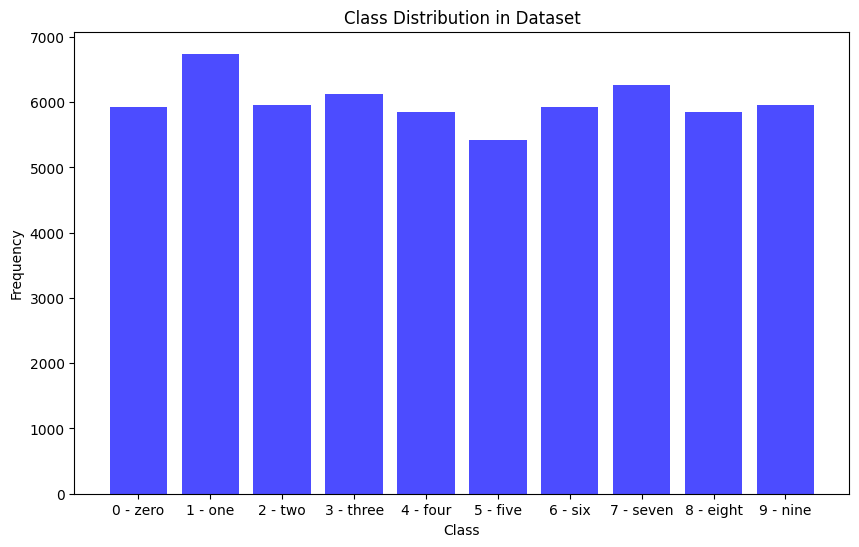

In [3]:
# Plot class distribution
plot_class_distribution(data)

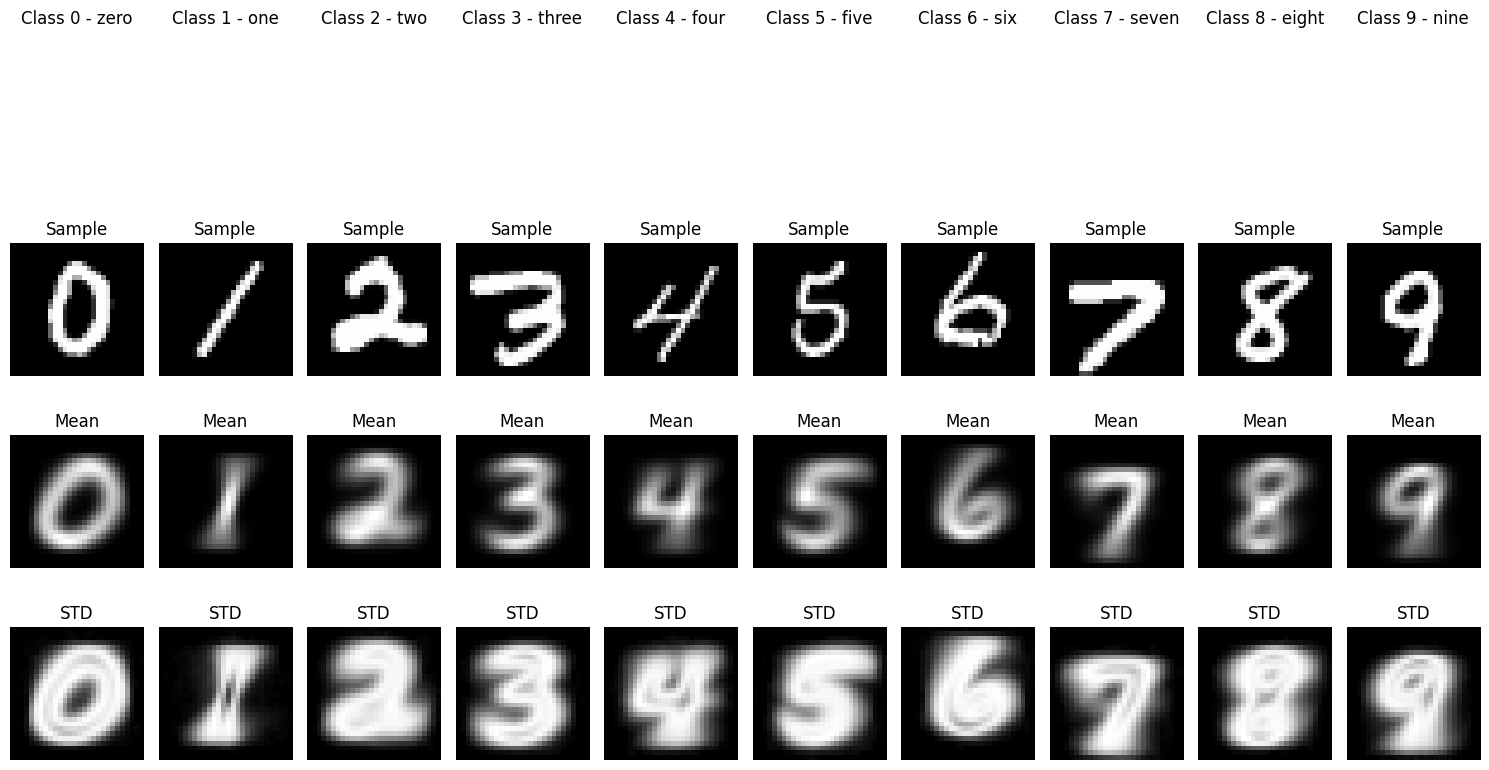

In [4]:
# Plot class visualizations
plot_class_visualizations(data, samples_per_class=1)

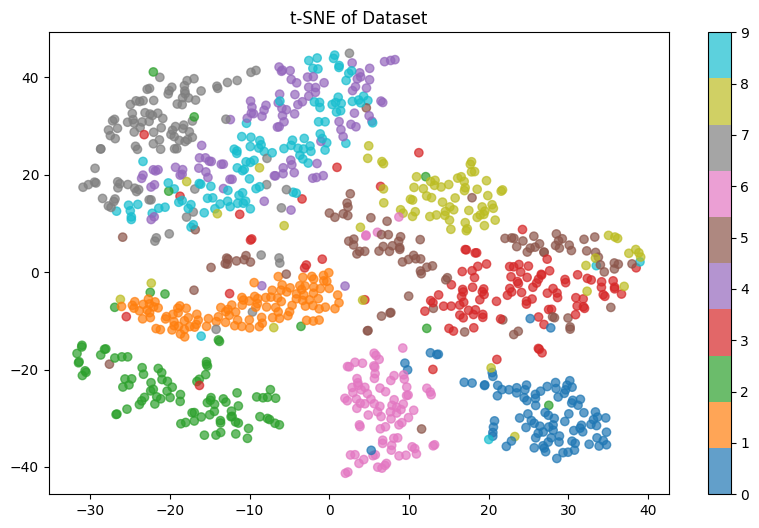

In [6]:
# Plot t-SNE
plot_tsne(data, subset_size=1000)